# Credit Card Fraud Detection

**Scenario.** A new credit card company in the western United States wants to market itself as one of the safest cards to use. As its data scientist, I was asked how accurately fraud can be predicted from transaction data, with one rule from the executive: **err on the side of caution**. Flagging a good transaction is acceptable; missing a fraud is not.

**Data.** 339,607 card transactions from 2019–2020 (DataCamp version of a Kaggle dataset), each labelled fraud or not. The data is **simulated** with a tool that imitates real card use, so patterns are cleaner than in a real bank.

**Contents:** 1. Data check · 2. Which purchases are risky? · 3. Fraud by state (map) · 4. Are older customers more at risk? · 5. Features a bank knows at payment time · 6. Model and alarm threshold · 7. Conclusions

In [1]:
import json
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score, recall_score, precision_score,
                             precision_recall_curve, confusion_matrix)
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
ACCENT, GREY, BLUE = "#C44E52", "#9A9A9A", "#4C72B0"

con = duckdb.connect("fraud.duckdb")
con.execute(open("sql/01_features.sql").read())   # builds the tables `transactions` and `features`
q = lambda sql: con.execute(sql).fetchdf()

## 1. Data check

In [2]:
q('''
SELECT COUNT(*)                                   AS transactions,
       COUNT(DISTINCT customer_id)                AS customers,
       SUM(is_fraud)                              AS frauds,
       ROUND(100 * AVG(is_fraud), 2)              AS fraud_pct,
       MIN(ts)::DATE AS first_day, MAX(ts)::DATE AS last_day,
       COUNT(DISTINCT state)                      AS states,
       COUNT(DISTINCT category)                   AS categories,
       COUNT(*) - COUNT(DISTINCT trans_num)       AS duplicate_ids
FROM transactions
''')

,transactions,customers,frauds,fraud_pct,first_day,last_day,states,categories,duplicate_ids
0,339607,187,1782.0,0.52,2019-01-01,2020-12-31,13,14,0


In [3]:
# Missing values in any column
q("SUMMARIZE transactions")[["column_name", "null_percentage"]].query("null_percentage != '0.00%'")

,column_name,null_percentage
0,customer_id,0.0
1,ts,0.0
2,trans_date_trans_time,0.0
3,merchant,0.0
4,category,0.0
5,amt,0.0
6,city,0.0
7,state,0.0
8,lat,0.0
9,long,0.0


In [4]:
# Is lat/long the purchase location (as the data dictionary says) or the cardholder's home?
q('''
SELECT MAX(n_home) AS max_home_locations_per_customer,
       MEDIAN(n_merchant_locations) AS median_merchant_locations_per_customer
FROM (SELECT customer_id, COUNT(DISTINCT (lat, long)) AS n_home,
             COUNT(DISTINCT (merch_lat, merch_long)) AS n_merchant_locations
      FROM transactions GROUP BY customer_id)
''')

,max_home_locations_per_customer,median_merchant_locations_per_customer
0,1,1472.0


- **No missing values, no duplicate transactions.** Fraud is rare: **1,782 of 339,607 (0.52%)**.
- **There is no card or customer ID.** Each cardholder has a unique date of birth, so date of birth + job + city identifies the **187 customers**.
- **The data dictionary is wrong about `lat`/`long`:** each customer has exactly one value, so it is the **cardholder's home**, not the purchase location. `merch_lat`/`merch_long` is where the purchase happened.
- **Accuracy is useless here:** a model that always says "not fraud" would be 99.48% accurate and catch nothing. I judge models on how many frauds they **catch (recall)** and how many alarms are real (**precision**).

## 2. Which purchases are most likely to be fraud?

In [5]:
cat = q('''
SELECT category, COUNT(*) AS transactions, SUM(is_fraud) AS frauds,
       ROUND(100 * AVG(is_fraud), 2) AS fraud_pct,
       ROUND(MEDIAN(amt) FILTER (WHERE is_fraud = 1), 0) AS median_fraud_amt,
       ROUND(MEDIAN(amt) FILTER (WHERE is_fraud = 0), 0) AS median_normal_amt
FROM transactions GROUP BY category ORDER BY fraud_pct DESC
''')
cat

,category,transactions,frauds,fraud_pct,median_fraud_amt,median_normal_amt
0,shopping_net,26379,381.0,1.44,996.0,8.0
1,grocery_pos,32732,433.0,1.32,313.0,113.0
2,misc_net,16898,217.0,1.28,799.0,10.0
3,shopping_pos,30329,187.0,0.62,870.0,8.0
4,gas_transport,35089,153.0,0.44,11.0,62.0
5,travel,10322,33.0,0.32,9.0,6.0
6,misc_pos,20024,62.0,0.31,30.0,12.0
7,grocery_net,11355,27.0,0.24,13.0,52.0
8,entertainment,24222,55.0,0.23,537.0,47.0
9,personal_care,24406,55.0,0.23,22.0,34.0


In [6]:
band = q('''
SELECT CASE WHEN amt < 50 THEN '1. under $50' WHEN amt < 200 THEN '2. $50–199'
            WHEN amt < 500 THEN '3. $200–499' WHEN amt < 1000 THEN '4. $500–999' ELSE '5. $1,000+' END AS amount_band,
       COUNT(*) AS transactions, SUM(is_fraud) AS frauds, ROUND(100 * AVG(is_fraud), 2) AS fraud_pct
FROM transactions GROUP BY 1 ORDER BY 1
''')
band

,amount_band,transactions,frauds,fraud_pct
0,1. under $50,178581,390.0,0.22
1,2. $50–199,144330,54.0,0.04
2,3. $200–499,12652,501.0,3.96
3,4. $500–999,2970,618.0,20.81
4,"5. $1,000+",1074,219.0,20.39


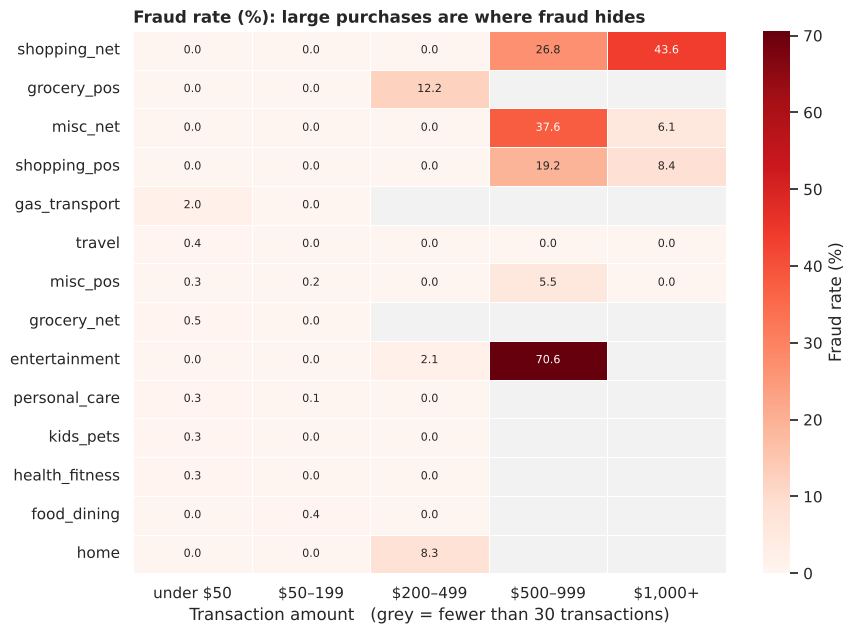

In [7]:
grid = q('''
SELECT category,
       CASE WHEN amt < 50 THEN 'under $50' WHEN amt < 200 THEN '$50–199'
            WHEN amt < 500 THEN '$200–499' WHEN amt < 1000 THEN '$500–999' ELSE '$1,000+' END AS amount_band,
       100 * AVG(is_fraud) AS fraud_pct, COUNT(*) AS n
FROM transactions GROUP BY 1, 2
''')
order_cols = ["under $50", "$50–199", "$200–499", "$500–999", "$1,000+"]
heat = grid.pivot(index="category", columns="amount_band", values="fraud_pct")[order_cols]
heat = heat.loc[cat["category"]]
counts = grid.pivot(index="category", columns="amount_band", values="n")[order_cols].loc[cat["category"]]
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.grid(False); ax.set_facecolor("#F2F2F2")
sns.heatmap(heat, mask=counts.isna() | (counts < 30), annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Fraud rate (%)"}, ax=ax,
            annot_kws={"size": 8}, linewidths=0.5)
ax.set_xlabel("Transaction amount   (grey = fewer than 30 transactions)"); ax.set_ylabel("")
ax.set_title("Fraud rate (%): large purchases are where fraud hides", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig("figures/fraud_by_category_amount.png", dpi=150); plt.show()

- **Online shopping (`shopping_net`), grocery in store (`grocery_pos`) and other online purchases (`misc_net`)** have the highest fraud rates, about **1.3–1.4%**, roughly 9 times the safest categories.
- **Amount matters more than category:** below $200 only about 0.1–0.2% of purchases are fraud; at **$200–499 it is 4%**, and **above $500 about 1 in 5 purchases is fraud**. Large online shopping purchases ($500+) are fraud in roughly a third of cases.
- The typical fraud is around **$350** against **$46** for a normal purchase.
- One exception: fraud at **gas stations and transport** is small (median about $11). Small test charges like this are a known pattern, used to check that a stolen card works before a big purchase.

## 3. Fraud rate by state

In [8]:
state = q('''
SELECT state, COUNT(*) AS transactions, SUM(is_fraud) AS frauds, 100 * AVG(is_fraud) AS fraud_pct,
       COUNT(DISTINCT customer_id) AS customers
FROM transactions GROUP BY state ORDER BY fraud_pct DESC
''')
state.round(2)

,state,transactions,frauds,fraud_pct,customers
0,AK,2963,50.0,1.69,4
1,OR,26408,197.0,0.75,18
2,NE,34425,216.0,0.63,19
3,CO,19766,115.0,0.58,13
4,NM,23427,121.0,0.52,13
5,CA,80495,402.0,0.50,45
6,MO,54904,262.0,0.48,30
7,WA,27040,126.0,0.47,13
8,HI,3649,16.0,0.44,2
9,WY,27776,119.0,0.43,12


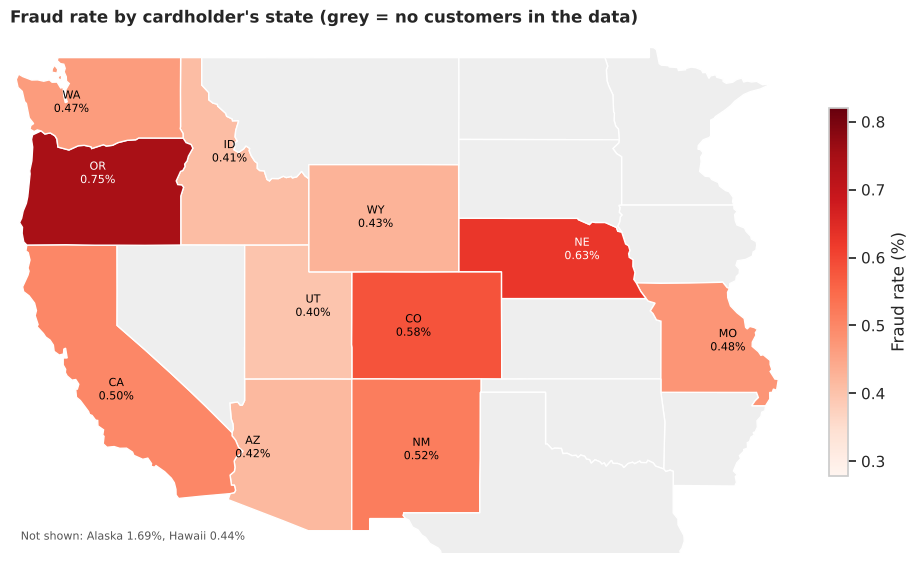

In [9]:
abbr = {"Alaska": "AK", "Arizona": "AZ", "California": "CA", "Colorado": "CO", "Hawaii": "HI", "Idaho": "ID",
        "Missouri": "MO", "Nebraska": "NE", "New Mexico": "NM", "Oregon": "OR", "Utah": "UT",
        "Washington": "WA", "Wyoming": "WY", "Nevada": "NV", "Montana": "MT", "North Dakota": "ND",
        "South Dakota": "SD", "Kansas": "KS", "Oklahoma": "OK", "Texas": "TX", "Iowa": "IA",
        "Arkansas": "AR", "Minnesota": "MN"}
geo = json.load(open("data/us_states.geojson"))
rates = state.set_index("state")["fraud_pct"]
shown = rates.drop(["AK", "HI"], errors="ignore")
cmap, norm = plt.cm.Reds, plt.Normalize(rates.min() * 0.7, shown.max() * 1.1)

def polygons(feature):
    g = feature["geometry"]
    rings = g["coordinates"] if g["type"] == "Polygon" else [p[0] for p in g["coordinates"]]
    return [np.array(r if g["type"] == "MultiPolygon" else r) for r in (rings if g["type"] == "MultiPolygon" else [rings[0]])]

fig, ax = plt.subplots(figsize=(10, 6.5))
for f in geo["features"]:
    name = f["properties"]["name"]
    if name not in abbr or name in ("Alaska", "Hawaii"):
        continue
    code_ = abbr[name]
    color = cmap(norm(rates[code_])) if code_ in rates else "#EEEEEE"
    for ring in polygons(f):
        ax.add_patch(Polygon(ring, closed=True, facecolor=color, edgecolor="white", linewidth=1))
    if code_ in rates:
        cx, cy = np.vstack(polygons(f)).mean(axis=0)
        ax.text(cx, cy, f"{code_}\n{rates[code_]:.2f}%", ha="center", va="center", fontsize=8,
                color="white" if rates[code_] > shown.quantile(0.8) else "black")
ax.set_xlim(-125, -89); ax.set_ylim(30.5, 50); ax.set_aspect(1.25); ax.axis("off")
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); fig.colorbar(sm, ax=ax, shrink=0.6, label="Fraud rate (%)")
ak, hi = rates.get("AK"), rates.get("HI")
ax.text(-124.5, 31, f"Not shown: Alaska {ak:.2f}%, Hawaii {hi:.2f}%", fontsize=8, color="#555555")
ax.set_title("Fraud rate by cardholder's state (grey = no customers in the data)", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig("figures/fraud_map.png", dpi=150); plt.show()

The map shows the fraud rate of cardholders in each state. Oregon (0.75%) and Nebraska (0.63%) are highest on the mainland and Alaska is highest overall (1.69%). **Be careful reading it:** the data has only 187 customers, and some states have very few (Alaska has 4 customers and Hawaii 2), so a single unlucky customer can move a state's rate a lot. The number of customers per state is in the table above. State is **not** a reliable signal of fraud in this data.

## 4. Are older customers more likely to be victims?

In [10]:
age = q('''
SELECT CASE WHEN age < 30 THEN '1. under 30' WHEN age < 45 THEN '2. 30–44' WHEN age < 60 THEN '3. 45–59'
            WHEN age < 75 THEN '4. 60–74' ELSE '5. 75+' END AS age_group,
       COUNT(*) AS transactions, SUM(is_fraud) AS frauds, ROUND(100 * AVG(is_fraud), 3) AS fraud_pct
FROM features GROUP BY 1 ORDER BY 1
''')
age

,age_group,transactions,frauds,fraud_pct
0,1. under 30,36187,242.0,0.669
1,2. 30–44,124867,437.0,0.350
2,3. 45–59,100376,561.0,0.559
3,4. 60–74,47729,315.0,0.660
4,5. 75+,30448,227.0,0.746


In [11]:
df_age = q("SELECT customer_id, age, is_fraud FROM features")
# (a) per transaction, with standard errors clustered by customer (one customer's transactions are not independent)
m = smf.logit("is_fraud ~ I(age / 10)", data=df_age).fit(disp=0, cov_type="cluster",
                                                        cov_kwds={"groups": df_age["customer_id"]})
odds_per_decade = np.exp(m.params.iloc[1])
ci = np.exp(m.conf_int().iloc[1])
print(f"Per transaction: odds of fraud x{odds_per_decade:.2f} per 10 years of age "
      f"(95% CI {ci[0]:.2f}–{ci[1]:.2f}, p = {m.pvalues.iloc[1]:.3f})")

# (b) per customer
cust = df_age.groupby("customer_id").agg(age=("age", "mean"), transactions=("is_fraud", "size"),
                                         frauds=("is_fraud", "sum"))
cust["older"] = np.where(cust["age"] >= 60, "60+", "under 60")
print(cust.groupby("older")[["transactions", "frauds"]].mean().round(1))
mw = stats.mannwhitneyu(cust.loc[cust.older == "60+", "frauds"], cust.loc[cust.older == "under 60", "frauds"])
print(f"Frauds per customer, 60+ vs under 60: Mann–Whitney p = {mw.pvalue:.2f}")

Per transaction: odds of fraud x1.10 per 10 years of age (95% CI 1.04–1.17, p = 0.002)
          transactions  frauds
older                         
60+             1426.3     9.8
under 60        1978.5     9.4
Frauds per customer, 60+ vs under 60: Mann–Whitney p = 0.37


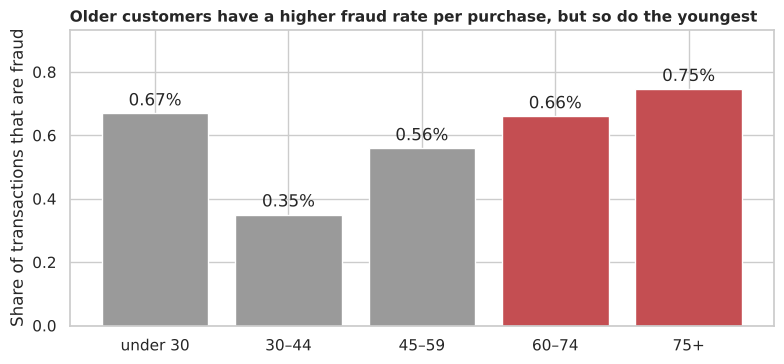

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = [a.split(". ")[1] for a in age["age_group"]]
bars = ax.bar(labels, age["fraud_pct"], color=[GREY, GREY, GREY, ACCENT, ACCENT])
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in age["fraud_pct"]], padding=3)
ax.set_ylabel("Share of transactions that are fraud")
ax.set_ylim(0, age["fraud_pct"].max() * 1.25)
ax.set_title("Older customers have a higher fraud rate per purchase, but so do the youngest", loc="left",
             fontweight="bold", fontsize=11)
fig.tight_layout(); fig.savefig("figures/fraud_by_age.png", dpi=150); plt.show()

**Answer: yes per purchase, no per person.**
- **Per transaction**, the fraud rate rises with age after 45, and the effect is statistically significant even when accounting for repeated transactions of the same customer (about **+10% odds per decade**, p ≈ 0.002). Customers 60+ have a rate of **0.69% vs 0.47%** under 60.
- **Per customer**, older and younger people suffer **about the same number of frauds** (around 10 each). Older customers simply make **fewer normal purchases**, so the same frauds are a bigger share of their card use.
- The pattern is U-shaped: customers **under 30** also have a high rate. The lowest is 30–44.

So older customers are not targeted more often, but fraud is a bigger part of their activity — worth extra protection (e.g. alerts) for them.

## 5. What a bank knows at the moment of payment

The features are built in SQL ([`sql/01_features.sql`](sql/01_features.sql)) with window functions over each customer's **earlier** transactions only, so the model never uses information from the future.

In [13]:
q('''
SELECT CASE WHEN is_fraud = 1 THEN 'fraud' ELSE 'normal' END AS transaction,
       ROUND(MEDIAN(amt), 0)                        AS median_amount,
       ROUND(MEDIAN(amt_vs_cust_avg), 2)            AS amount_vs_customer_usual,
       ROUND(100 * AVG(is_night::INT), 0)           AS pct_at_night_22_to_4,
       ROUND(AVG(txn_count_1h), 2)                  AS txns_in_previous_hour,
       ROUND(MEDIAN(secs_since_prev) / 60, 0)       AS minutes_since_previous,
       ROUND(100 * AVG(is_new_merchant::INT), 0)    AS pct_new_merchant,
       ROUND(MEDIAN(distance_km), 0)                AS km_home_to_merchant
FROM features GROUP BY 1
''')

,transaction,median_amount,amount_vs_customer_usual,pct_at_night_22_to_4,txns_in_previous_hour,minutes_since_previous,pct_new_merchant,km_home_to_merchant
0,normal,46.0,0.65,23.0,0.19,264.0,29.0,78.0
1,fraud,356.0,4.10,86.0,0.73,73.0,47.0,77.0


Frauds are **about 4 times the customer's usual amount**, **86% happen at night** (22:00–04:00, vs 23% of normal purchases), come in **quick bursts** (the previous transaction was ~70 minutes earlier, vs ~4.5 hours), and are more often at a **new merchant**. Distance from home does not differ, so it is not useful here.

## 6. Model and alarm threshold

**Time-based split**, like a bank using last year's data to protect next year: train on **Jan 2019 – Jun 2020**, test on **Jul – Dec 2020** (never touched until the final evaluation).
**Threshold rule (the executive's "err on the side of caution"):** the alarm level is set on a separate earlier period (train on 2019, choose the level on Jan–Jun 2020) so that the model **catches at least 95% of frauds**; that fixed level is then applied to the test months.

In [14]:
df = q("SELECT * FROM features ORDER BY ts, trans_num")
num = ["amt", "hour", "day_of_week", "age", "city_pop", "distance_km", "txn_count_1h", "txn_count_24h",
       "amt_sum_24h", "cust_avg_amt_30d", "secs_since_prev", "prior_txn_count", "amt_vs_cust_avg"]
X = pd.concat([df[num].astype(float),
               df[["is_night", "is_weekend", "is_new_merchant"]].astype(int),
               pd.get_dummies(df["category"], prefix="cat", dtype=int)], axis=1)
X["log_amt"] = np.log1p(df["amt"])
X["secs_since_prev"] = X["secs_since_prev"].fillna(1e7)        # first transaction of a customer
X = X.fillna(X.median())
y = df["is_fraud"].to_numpy()

train = (df["ts"] < "2020-07-01").to_numpy(); test = ~train
fit_part = (df["ts"] < "2020-01-01").to_numpy(); val_part = train & ~fit_part
print(f"train: {train.sum():,} transactions, {y[train].sum()} frauds | test: {test.sum():,} transactions, {y[test].sum()} frauds")

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Gradient boosting (scikit-learn)": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, early_stopping=False, random_state=0),
    "XGBoost": XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=5, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="aucpr", n_jobs=1, random_state=0),
}
TARGET_RECALL = 0.95
rows, scores = [], {}
test_days = df.loc[test, "ts"].dt.date.nunique()
for name, model in models.items():
    model.fit(X[fit_part], y[fit_part])
    p_val = model.predict_proba(X[val_part])[:, 1]
    threshold = np.quantile(p_val[y[val_part] == 1], 1 - TARGET_RECALL)
    model.fit(X[train], y[train])
    p_test = model.predict_proba(X[test])[:, 1]
    scores[name] = p_test
    flag = p_test >= threshold
    rows.append({"model": name,
                 "PR-AUC": average_precision_score(y[test], p_test),
                 "ROC-AUC": roc_auc_score(y[test], p_test),
                 "frauds caught (recall)": recall_score(y[test], flag),
                 "alarms that are fraud (precision)": precision_score(y[test], flag),
                 "share of transactions flagged": flag.mean(),
                 "false alarms per day": (flag & (y[test] == 0)).sum() / test_days,
                 "threshold": threshold})
results = pd.DataFrame(rows).set_index("model")
print(results.round(4).to_string())
results.style.format({"PR-AUC": "{:.3f}", "ROC-AUC": "{:.4f}", "frauds caught (recall)": "{:.1%}",
                      "alarms that are fraud (precision)": "{:.1%}", "share of transactions flagged": "{:.2%}",
                      "false alarms per day": "{:.1f}", "threshold": "{:.4f}"})

train: 243,168 transactions, 1408 frauds | test: 96,439 transactions, 374 frauds


                                  PR-AUC  ROC-AUC  frauds caught (recall)  alarms that are fraud (precision)  share of transactions flagged  false alarms per day  threshold
model                                                                                                                                                                       
Logistic regression               0.2956   0.9779                  0.9519                             0.0388                         0.0952               47.9457     0.1652
Gradient boosting (scikit-learn)  0.8057   0.9871                  0.9358                             0.3850                         0.0094                3.0380     0.0004
XGBoost                           0.9101   0.9973                  0.9439                             0.4896                         0.0075                2.0000     0.0084


,PR-AUC,ROC-AUC,frauds caught (recall),alarms that are fraud (precision),share of transactions flagged,false alarms per day,threshold
model,,,,,,,
Logistic regression,0.296,0.9779,95.2%,3.9%,9.52%,47.9,0.1652
Gradient boosting (scikit-learn),0.806,0.9871,93.6%,38.5%,0.94%,3.0,0.0004
XGBoost,0.910,0.9973,94.4%,49.0%,0.75%,2.0,0.0084


**XGBoost is the best model.** At the cautious threshold it catches **94% of frauds** in months it has never seen, while flagging **under 1% of all transactions**; about **half of its alarms are real frauds**, which means roughly **2 false alarms a day** for the whole card portfolio. Logistic regression reaches the same catch rate only by flagging about 9.5% of transactions (about 48 false alarms a day), because fraud depends on combinations (night **and** a large amount **and** a busy card) that a straight-line model cannot capture.

In [15]:
best = "XGBoost"
p = scores[best]; thr = results.loc[best, "threshold"]
tn, fp, fn, tp = confusion_matrix(y[test], p >= thr).ravel()
print(f"Test period ({test_days} days): {tp} frauds caught, {fn} missed, {fp} good transactions flagged, {tn:,} correctly passed")

Test period (184 days): 353 frauds caught, 21 missed, 368 good transactions flagged, 95,697 correctly passed


In [16]:
# The trade-off the executive can choose: how many frauds to catch vs how many false alarms
prec, rec, thr_curve = precision_recall_curve(y[test], p)
options = []
for target in [0.80, 0.90, 0.95, 0.98, 0.99]:
    i = np.where(rec[:-1] >= target)[0][-1]
    flagged = (p >= thr_curve[i])
    options.append({"frauds caught": f"{rec[i]:.0%}", "frauds missed (of 374)": int(round((1 - rec[i]) * y[test].sum())),
                    "false alarms per day": round((flagged & (y[test] == 0)).sum() / test_days, 1),
                    "alarms that are fraud": f"{prec[i]:.0%}"})
tradeoff = pd.DataFrame(options); tradeoff

,frauds caught,frauds missed (of 374),false alarms per day,alarms that are fraud
0,80%,74,0.1,92%
1,90%,37,0.8,70%
2,95%,18,5.6,26%
3,98%,7,18.6,10%
4,99%,3,47.5,4%


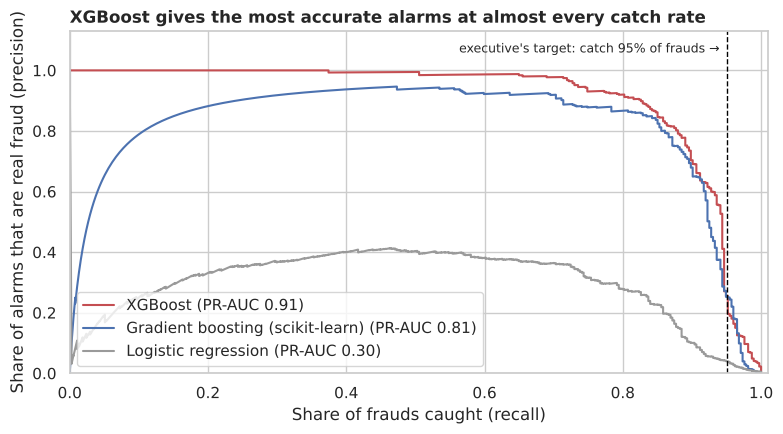

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, color in [("XGBoost", ACCENT), ("Gradient boosting (scikit-learn)", BLUE), ("Logistic regression", GREY)]:
    pr, rc, _ = precision_recall_curve(y[test], scores[name])
    ax.plot(rc, pr, color=color, label=f"{name} (PR-AUC {results.loc[name, 'PR-AUC']:.2f})")
ax.axvline(0.95, color="black", linestyle="--", linewidth=1)
ax.text(0.94, 1.07, "executive's target: catch 95% of frauds →", ha="right", va="center", fontsize=9)
ax.set_xlabel("Share of frauds caught (recall)"); ax.set_ylabel("Share of alarms that are real fraud (precision)")
ax.set_xlim(0, 1.01); ax.set_ylim(0, 1.13); ax.set_yticks(np.arange(0, 1.01, 0.2)); ax.legend(loc="lower left")
ax.set_title("XGBoost gives the most accurate alarms at almost every catch rate", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig("figures/precision_recall.png", dpi=150); plt.show()

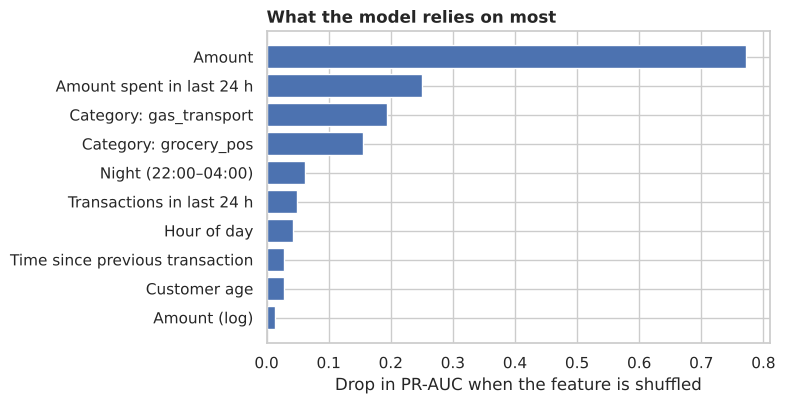

amt                  0.7722
amt_sum_24h          0.2499
cat_gas_transport    0.1942
cat_grocery_pos      0.1549
is_night             0.0613
txn_count_24h        0.0482
hour                 0.0426
secs_since_prev      0.0289
age                  0.0273
log_amt              0.0143
dtype: float64

In [18]:
from sklearn.inspection import permutation_importance
xgb = models[best]
sample = np.where(test)[0]
pi = permutation_importance(xgb, X.iloc[sample], y[sample], scoring="average_precision", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False).head(10)
nice = {"amt": "Amount", "log_amt": "Amount (log)", "hour": "Hour of day", "is_night": "Night (22:00–04:00)",
        "amt_vs_cust_avg": "Amount vs customer's usual", "cust_avg_amt_30d": "Customer's usual amount (30 days)",
        "txn_count_1h": "Transactions in last hour", "txn_count_24h": "Transactions in last 24 h",
        "amt_sum_24h": "Amount spent in last 24 h", "secs_since_prev": "Time since previous transaction",
        "age": "Customer age", "prior_txn_count": "Customer history length", "city_pop": "City population",
        "is_new_merchant": "New merchant for customer", "distance_km": "Distance home → merchant", "day_of_week": "Day of week"}
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([nice.get(c, c.replace("cat_", "Category: ")) for c in imp.index][::-1], imp.values[::-1], color=BLUE)
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title("What the model relies on most", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig("figures/feature_importance.png", dpi=150); plt.show()
imp.round(4)

## 7. Conclusions for the executive

1. **Fraud can be predicted very well.** On six months the model had never seen, it caught **353 of 374 frauds (94%)** while flagging **less than 1% of transactions**; about **half of the alarms were real fraud** (about 2 false alarms a day).
2. **It follows the "err on the side of caution" rule.** The alarm level was fixed in advance to catch 95% of frauds; moving it is a business choice (see the trade-off table): catching 98% is possible at about 19 false alarms a day, 99% at about 48.
3. **What fraud looks like:** large purchases (several times the customer's usual amount), at **night**, in **quick bursts**, often **online shopping** or **in-store groceries**, sometimes preceded by small test charges at gas stations.
4. **Older customers** have a higher fraud rate per purchase but not more frauds per person; extra alerts for them are a cheap safety measure.

**Next steps:** send flagged transactions to a quick check (SMS or app confirmation) rather than blocking them; retrain monthly; test on real (not simulated) transactions before relying on these numbers, since simulated data has cleaner patterns than real fraud.

**Limits:** simulated data; only 187 customers; the cost of a false alarm and of a missed fraud were not given, so the threshold follows the executive's instruction rather than a cost calculation.